# Quelles bagues contrôler en priorité ?

Au chapitre précédent, tu as regroupé des abonnés dont les habitudes se ressemblaient. Dans l’atelier de mécanique qui t’accueille aujourd’hui, les pièces déjà fabriquées ont une fiche de contrôle. Un inspecteur y a consigné son verdict pour chacune. L’atelier aimerait se servir de ces verdicts pour choisir l’ordre des prochains contrôles.

Un **tour** fait tourner le métal pendant qu’un outil lui donne sa forme. Celui de l’atelier fabrique des anneaux, les **bagues**. À la sortie du tour, un pied à coulisse permet de mesurer leur diamètre, la largeur d’un bord à l’autre en passant par le centre. Chaque bague rejoint alors la file ordinaire ou la file prioritaire. Toutes finissent par être inspectées.

> « Quelles pièces devons-nous examiner en premier ? Combien de pièces défectueuses resteraient dans la file ordinaire ? »
>
> *La responsable de l’atelier*

Tu vas essayer une règle de tri sur des bagues déjà inspectées. Pour que l’essai ressemble à une journée dans l’atelier, imagine d’abord la décision à prendre devant une bague qui vient de sortir du tour.

<details><summary><strong>Sommaire du chapitre</strong></summary>

- [Réserver des pièces pour juger la règle](#cell-id=e6b0ac95)
- [Choisir les mesures disponibles à la sortie du tour](#cell-id=dcded56a)
- [Voir si le diamètre permet de repérer les défauts](#cell-id=55b5a10b)
- [Essayer une règle de priorité](#cell-id=6d492a8a)
- [Comparer les règles sur les mêmes bagues](#cell-id=a64f6abb)
- [Évaluer le choix sur les bagues mises de côté](#cell-id=fe0b09d0)
- [Présenter le résultat à la responsable](#cell-id=atelier-restitution)
- [Retenir les décisions qui expliquent le bilan](#cell-id=atelier-synthese)

</details>

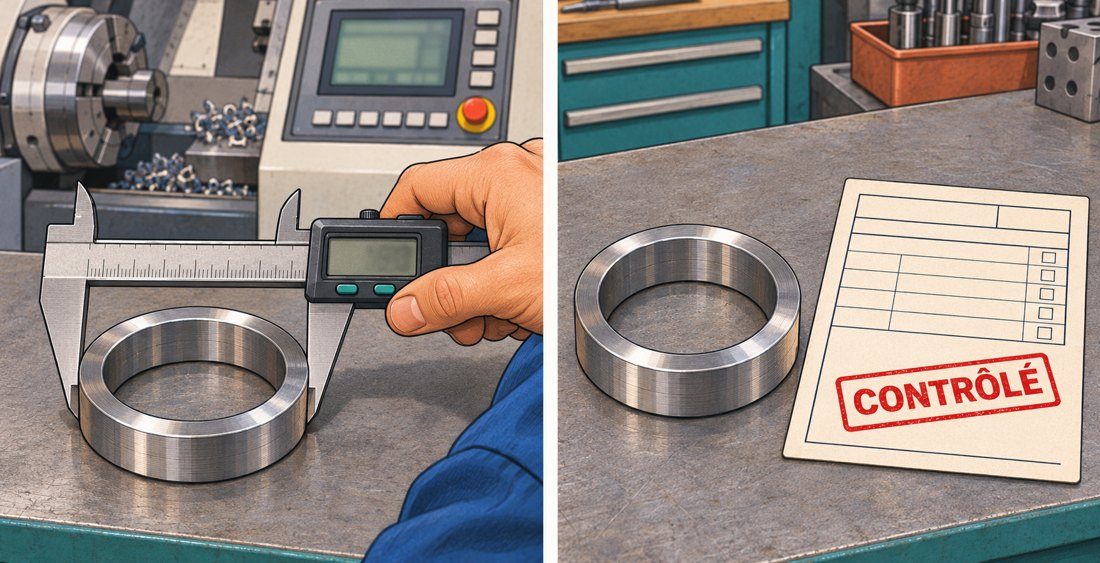

### Se placer au moment du tri

> Regarde le pied à coulisse et la fiche tamponnée. Lequel des deux te donne déjà une information au moment de choisir une file ?

Complète la phrase sur ton brouillon. « Pour chaque …, au moment où …, j’utilise … pour décider si … . Je connaîtrai le vrai verdict quand … . »

<details><summary>Comparer ma formulation à celle de l’atelier</summary>

Je peux mesurer la bague dès sa sortie du tour et décider si elle passe en priorité. J’apprendrai si elle était réellement défectueuse quand l’inspection sera terminée, quelle que soit la file empruntée.

</details>

## 1. Mettre de côté les pièces qui serviront à juger la règle

Tu as situé le tri avant l’inspection. Sur la fiche d’une ancienne bague, tu peux retrouver les deux moments. Le diamètre et, quand elle a été enregistrée, la vibration de la machine ont été mesurés avant le contrôle. Plus tard, l’inspecteur a indiqué si la bague était conforme et ce qu’elle allait devenir.

Le tableau reproduit **1 200 bagues simulées**, une par lot de fabrication tiré indépendamment. Chaque ligne rassemble les informations d’une fiche.

| Colonne | Ce que tu y trouves |
|---|---|
| `id_piece` | Numéro de la bague, pour retrouver sa fiche |
| `machine` | Tour A, B ou C |
| `diametre_mm` | Diamètre à la sortie du tour, en millimètres. Le plan demande 20 mm. |
| `vibration_mm_s` | Vibration de la machine pendant la fabrication, mesurée en millimètres par seconde (mm/s). Le relevé manque parfois. |
| `outil_h` | Nombre d’heures de service de l’outil |
| `destination_finale` | Après l’inspection, la pièce est rangée (stock), reprise pour correction (retouche) ou écartée (rebut). |
| `defaut` | Verdict de l’inspection. 1 signifie « défectueuse », 0 « conforme ». |

> **Charger les fiches.** Sélectionne la cellule de code repliée ci-dessous et appuie sur **Maj + Entrée**. Elle lit les 1 200 lignes incluses dans le notebook et donne au tableau le nom `donnees`.

<details><summary>Choisir Python ou installer une bibliothèque manquante</summary>

Après avoir extrait le ZIP, ouvre son dossier dans Jupyter ou VS Code et sélectionne ton environnement Python. Le *noyau* est le Python qui exécutera tes cellules. Exécute les blocs de code dans l’ordre. Si Python signale qu’une bibliothèque manque (par exemple pandas, qui sert à manipuler les tableaux), depuis le dossier du cahier, exécute `%pip install -r ../requirements.txt` dans une cellule. Redémarre ensuite le noyau. L’installation nécessite Internet. Les données et les illustrations sont incluses dans le notebook.

La cellule de chargement cherche le fichier du chapitre dans le dossier ouvert. La fonction `tableau_du_cahier()` en lit le tableau intégré. `pd.read_csv` transforme les lignes de texte en un tableau pandas et `len(donnees)` en compte les lignes.

</details>

In [1]:
from pathlib import Path
from io import StringIO
import json
import os
import pandas as pd

def tableau_du_cahier():
    # Jupyter et VS Code peuvent fournir le chemin du notebook ouvert.
    chemins = [Path(globals().get("__vsc_ipynb_file__") or "."),
               Path(os.environ.get("JPY_SESSION_NAME") or "."),
               Path('04_Projet_controle_qualite.ipynb'),
               Path('exos/04_Projet_controle_qualite.ipynb')]
    # Si le fichier a été renommé, le retrouver dans le dossier ouvert.
    for chemin in [*chemins, *Path.cwd().glob("*.ipynb")]:
        if chemin.suffix != ".ipynb" or not chemin.is_file():
            continue
        with chemin.open(encoding="utf-8-sig") as fichier:
            table = json.load(fichier).get("metadata", {}).get("tableau_du_cours", {})
        if table.get("cahier") == 'jour-4':
            return pd.read_csv(StringIO(table["csv"]))
    raise FileNotFoundError("Ouvre le dossier du notebook dans Jupyter ou VS Code, puis relance cette cellule.")

donnees = tableau_du_cahier()
print(len(donnees), "lignes chargées.")

1200 lignes chargées.


Tu disposes de 1 200 fiches avec leur verdict. Si tu les utilises toutes pour construire et choisir la règle, avec quelles pièces pourras-tu encore évaluer la règle une fois choisie ?

Avant de regarder les mesures, mets 240 bagues de côté pour cet essai final. Parmi les 960 restantes, réserve encore 240 bagues pour comparer plusieurs règles. Les 720 autres serviront à apprendre le lien entre les mesures et les défauts.

| Nom du lot dans le code | Usage des fiches |
|---|---|
| `apprentissage` | Apprendre à partir des mesures et des verdicts. |
| `validation` | Comparer les règles et décider laquelle garder. |
| `test` | Juger la règle retenue sur des bagues restées à l’écart des choix. |

Dans la cellule suivante, chaque appel à `train_test_split` partage les lignes au hasard en deux groupes. `test_size` indique la fraction à mettre de côté à ce tirage.

In [2]:
from sklearn.model_selection import train_test_split

reste, test = train_test_split(
    donnees, test_size=0.20, stratify=donnees["defaut"], random_state=41
)
apprentissage, validation = train_test_split(
    reste, test_size=0.25, stratify=reste["defaut"], random_state=57
)
print("Apprentissage, validation, test :", len(apprentissage), len(validation), len(test))

Apprentissage, validation, test : 720 240 240


Tu dois lire **720, 240, 240**. Le premier tirage réserve 20 % des 1 200 pièces pour le test. Le deuxième en réserve 25 % parmi les 960 restantes pour la validation. `stratify` conserve à peu près la même proportion de défauts dans chaque lot. `random_state` fixe le tirage. Les valeurs 41 et 57 permettent de retrouver les mêmes pièces à chaque exécution.

Tu peux maintenant consulter les 720 fiches d’apprentissage. Quelles colonnes pourrais-tu réellement renseigner si tu tenais l’une de ces bagues à la sortie du tour ?

## 2. Choisir ce que la règle pourra voir

Le diamètre se mesure à temps. Encore faut-il l’exprimer d’une façon qui aide à reconnaître un défaut. Une bague de 19,95 mm et une de 20,05 mm s’écartent autant des 20 mm demandés.

> Exécute la cellule, puis modifie la dernière ligne pour obtenir la distance au diamètre demandé dans les deux cas. Reprends ensuite les colonnes de la fiche. Laquelle donne le verdict à apprendre ? Laquelle révélerait le résultat trop tôt ?

In [3]:
diametres = pd.Series([19.95, 20.05])
difference = diametres - 20
print(difference.round(2).tolist())

[-0.05, 0.05]


Dans le code, `pd.Series` range les deux diamètres dans une colonne de nombres. Soustraire 20 donne −0,05 et +0,05 mm. Le signe indique de quel côté du diamètre demandé se trouve la pièce. `.round(2)` arrondit à deux décimales et `.tolist()` présente les résultats sous forme de liste.

<details><summary>Indice pour le calcul et le choix des colonnes</summary>

La valeur absolue d’un nombre enlève son signe. En pandas, essaie `.abs()` juste avant `.round(2)`. Pour choisir les colonnes, demande-toi qui pouvait les remplir avant l’inspection.

</details>

<details><summary>Vérifier mon choix</summary>

`difference.abs().round(2).tolist()` donne `[0.05, 0.05]`. Les deux bagues ont un écart de 0,05 mm.

Le verdict à apprendre se trouve dans `defaut`. Si la règle voyait « rebut » dans `destination_finale`, elle bénéficierait d’une décision prise après l’inspection. Introduire dans les données de la règle un tel indice indisponible au moment du tri s’appelle une **fuite de données**.

</details>

La cellule suivante met de côté le verdict et le numéro de pièce. Dans cette simulation, le numéro sert à retrouver la fiche. La règle, elle, reçoit le tour, la vibration, les heures de service de l’outil et la distance à 20 mm.

In [4]:
def mesures(table):
    x = table[["machine", "vibration_mm_s", "outil_h"]].copy()
    x["ecart_mm"] = (table["diametre_mm"] - 20).abs()
    return x

x_app = mesures(apprentissage)
y_app = apprentissage["defaut"]
print(x_app.head(3))

     machine  vibration_mm_s  outil_h  ecart_mm
1163       C            2.95     29.2     0.005
319        B            2.73     27.4     0.034
1098       A            2.32     44.5     0.048


`head(3)` affiche trois exemples. Lis le premier. La bague vient du tour C, la vibration vaut 2,95 mm/s, l’outil a servi 29,2 heures et le diamètre s’écarte de 0,005 mm du plan. La fonction `mesures` construit ces quatre colonnes pour n’importe quel lot. `.copy()` lui donne une copie de travail et `.abs()` calcule la distance à 20 mm.

Pour le lot d’apprentissage, les mesures s’appellent `x_app`. Les verdicts correspondants sont rangés dans le même ordre dans `y_app`. Tu peux donc prendre un écart de diamètre et vérifier ce que l’inspecteur a conclu pour cette bague.

## 3. Le diamètre suffit-il ?

Tu peux maintenant comparer les écarts des bagues conformes avec ceux des défectueuses. Imagine que tu ranges les écarts du plus petit au plus grand dans chaque groupe. La valeur du milieu donne l’écart **médian**. Quand il y a deux valeurs au milieu, leur moyenne donne la **médiane**.

> Prédis dans quel groupe cette médiane sera la plus élevée, puis lance la cellule. Regarde ensuite les bagues dont l’écart est compris entre 0,035 et 0,045 mm. La dernière ligne donne leur nombre. Retrouve le verdict de ces seules bagues.

<details><summary>Suivre le calcul dans le code</summary>

`value_counts()` compte les verdicts 0 et 1. `sort_index()` les remet dans cet ordre et `to_dict()` affiche le nombre associé à chacun. Pour les vibrations, `isna()` repère les cases vides et `sum()` les compte. Enfin, `groupby(y_app)` sépare les écarts selon le verdict avant que `median()` calcule la valeur du milieu dans chaque groupe.

</details>

In [5]:
print("Pièces par verdict :", y_app.value_counts().sort_index().to_dict())
print("Vibrations manquantes :", x_app["vibration_mm_s"].isna().sum())
print("Écart médian par verdict (mm) :", x_app["ecart_mm"].groupby(y_app).median())
zone = x_app["ecart_mm"].round(3).between(0.035, 0.045)
print("Pièces dans la zone :", zone.sum())

Pièces par verdict : {0: 614, 1: 106}
Vibrations manquantes : 52
Écart médian par verdict (mm) : defaut
0    0.0260
1    0.0525
Name: ecart_mm, dtype: float64
Pièces dans la zone : 89


Sur les 720 pièces d’apprentissage, 614 sont conformes et 106 sont défectueuses. L’écart médian est plus élevé chez les défectueuses (0,0525 mm contre 0,026 mm). Cela ne dit pas encore dans quel groupe ranger une bague dont l’écart est par exemple de 0,040 mm. La dernière ligne compte 89 pièces dans la tranche qui nous intéresse, tous verdicts confondus.

<details><summary>Indice pour compter dans la zone</summary>

`between(0.035, 0.045)` vérifie l’intervalle après arrondi au millième de millimètre. `zone` vaut vrai pour chaque bague située entre les deux bornes incluses. `y_app[zone]` garde le verdict de ces seules bagues. Applique-lui la méthode de comptage de la première ligne.

</details>

<details><summary>Vérifier mon observation</summary>

`print(y_app[zone].value_counts())` donne **70 conformes et 19 défectueuses**. Un grand écart attire donc l’attention, mais connaître cette seule tranche ne suffit pas à déterminer le verdict d’une bague.

</details>

## 4. Essayer une règle de priorité

Si l’atelier place les 89 bagues de cette tranche en priorité, 70 conformes occupent une place dans cette file. S’il les laisse toutes dans la file ordinaire, 19 défectueuses attendent leur tour. Comment départager deux règles de tri quand elles ne commettent pas les mêmes erreurs ?

Une pièce conforme envoyée en priorité est une **fausse alerte**. L’atelier lui attribue un point de pénalité. Une pièce défectueuse laissée en file ordinaire est un **défaut manqué**. Elle coûte six points. Une bague dirigée vers la bonne file ne coûte aucun point.

| Verdict de l’inspection | File ordinaire | File prioritaire |
|---|---:|---:|
| Pièce défectueuse | **6 points** | 0 point |
| Pièce conforme | 0 point | **1 point** |

> Calcule le coût de trois défauts manqués et de huit fausses alertes.

<details><summary>Vérifier mon calcul</summary>

Trois défauts manqués coûtent 18 points. Avec les huit fausses alertes, le total atteint **26 points**. On préférera la règle qui donne la pénalité la plus basse.

</details>

Pour tenter d’abaisser cette pénalité, essaie de tenir compte des quatre mesures disponibles. Le comptage sur les 720 pièces a toutefois révélé **52 vibrations manquantes**. Quel nombre donner à la règle quand la case d’une bague est vide ? La cellule ci-dessous prépare les fiches avant le premier essai.

In [6]:
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

nombres = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
preparation = make_column_transformer(
    (nombres, ["ecart_mm", "vibration_mm_s", "outil_h"]),
    (OneHotEncoder(handle_unknown="ignore"), ["machine"])
)
entrees_app = preparation.fit_transform(x_app)
entrees_val = preparation.transform(mesures(validation))

Imagine une bague du tour B dont la vibration manque. La case vide reçoit la médiane des vibrations relevées sur le lot d’apprentissage. Les trois mesures numériques sont ensuite ramenées à une échelle comparable. Pour indiquer la machine d’origine, la case B vaut 1 et les cases A et C valent 0. On peut à présent traiter cette fiche comme les autres.

<details><summary>Retrouver cette préparation dans la cellule</summary>

`SimpleImputer(strategy="median")` complète les cases vides. `StandardScaler` soustrait ensuite à chaque nombre la moyenne de sa colonne et le divise par l’écart-type, la mesure de dispersion vue au chapitre précédent. Les heures et les millimètres s’expriment ainsi sur des échelles comparables. `make_pipeline` enchaîne ces deux opérations.

`OneHotEncoder` crée une colonne par tour connu. Avec `handle_unknown="ignore"`, si un nouveau tour apparaît lors du tri, toutes les cases de tour restent à zéro. `make_column_transformer` applique chaque traitement aux colonnes indiquées. `fit_transform` détermine les réglages à partir des 720 pièces d’apprentissage, puis prépare leurs mesures. `transform` reprend ces réglages pour la validation.

</details>

Avec ces fiches prêtes, essaie d’abord la consigne la plus simple, « tout en file ordinaire ». Elle te donnera un coût de référence. Pour voir si l’on peut faire mieux, essaie ensuite deux façons d’estimer le risque d’un défaut. La **régression logistique** du chapitre 2 combine les mesures en donnant un poids à chacune. Un **arbre de décision** les examine par questions successives, par exemple « l’écart dépasse-t-il une certaine valeur ? ». Dans le code ci-dessous, l’arbre peut poser jusqu’à quatre questions de suite pour une même bague.

In [7]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

modeles = {
    "File ordinaire": DummyClassifier(strategy="constant", constant=0),
    "Logistique": LogisticRegression(max_iter=500),
    "Arbre": DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, random_state=7)
}
scores_val = {}
for nom, modele in modeles.items():
    modele.fit(entrees_app, y_app)
    scores_val[nom] = modele.predict_proba(entrees_val)[:, 1]

Les noms « File ordinaire », « Logistique » et « Arbre » correspondent aux trois choix que la boucle essaie à tour de rôle. Pour les deux modèles qui apprennent, `fit(entrees_app, y_app)` ajuste la règle à partir des mesures et des verdicts des mêmes bagues. `predict_proba` donne ensuite à chaque bague de validation deux nombres entre 0 et 1, un pour « conforme » et un pour « défaut ». `[:, 1]` garde le second pour toutes les bagues. Plus ce **score** est élevé, plus le modèle juge un défaut probable.

Pour passer du score à une file, l’atelier fixe une limite, le **seuil**. Une bague ayant un score de 0,20 reste en file ordinaire au seuil de 0,50. Si tu abaisses le seuil à 0,15, la même bague passe en priorité. En Python, `>=` signifie « supérieur ou égal ». Une bague au seuil exact passe aussi en priorité.

> Fais l’essai avec la régression logistique. Lance la cellule une première fois, puis remplace 0,50 par 0,15 (écris `0.15` dans le code). Avant de la relancer, prédis ce qui va arriver au nombre d’alertes et au nombre de défauts manqués.

<details><summary>Lire les réglages des trois règles dans le code précédent</summary>

`DummyClassifier` donne la même réponse à chaque pièce. `constant=0` lui fait toujours proposer la file ordinaire. `LogisticRegression` ajuste les poids des mesures sur les fiches d’apprentissage. `max_iter=500` limite le nombre d’étapes de calcul pour cet ajustement. Pour l’arbre, `max_depth=4` limite la longueur du chemin à quatre questions et `min_samples_leaf=20` garde au moins vingt fiches d’apprentissage dans chaque groupe final. `scores_val[nom]` range les scores de validation sous le nom de la règle utilisée.

</details>

In [8]:
def bilan(verdicts, alertes):
    fausses = int(((verdicts == 0) & alertes).sum())
    manques = int(((verdicts == 1) & ~alertes).sum())
    return {"prioritaires": int(alertes.sum()), "fausses alertes": fausses,
            "défauts manqués": manques, "pénalité": fausses + 6 * manques}

seuil_essai = 0.50
print(bilan(validation["defaut"], scores_val["Logistique"] >= seuil_essai))

{'prioritaires': 7, 'fausses alertes': 2, 'défauts manqués': 31, 'pénalité': 188}


`bilan` reçoit les verdicts et les décisions prises en comparant les scores au seuil. Ces décisions valent vrai pour les pièces prioritaires et faux pour les autres. Pour compter les fausses alertes, `&` exige à la fois un verdict « conforme » et une alerte. Pour compter les défauts manqués, `~alertes` repère les bagues restées en file ordinaire. Chaque `.sum()` compte les lignes qui remplissent la condition.

<details><summary>Vérifier mon essai</summary>

Au seuil de 0,50, 7 pièces partent en priorité, dont 2 conformes, et 31 défauts passent en file ordinaire. La pénalité atteint 188 points. À 0,15, la régression envoie **69 pièces en priorité**, dont 45 conformes, et laisse en file ordinaire 12 défectueuses. Sa pénalité descend à **117 points**. Pour l’atelier, les 19 défauts supplémentaires repérés économisent 114 points, assez pour couvrir les 43 fausses alertes de plus.

</details>

## 5. Choisir sur la validation

Le deuxième essai a réduit la pénalité de la régression. Est-ce que 0,15 reste le meilleur seuil quand tu compares davantage de seuils et que tu inclus l’arbre dans l’essai ?

La cellule essaie les seuils 0,05, 0,10, 0,15 et ainsi de suite jusqu’à 1. Elle ajoute 1,01 pour qu’aucun score, même égal à 1, ne puisse déclencher d’alerte. Pour la règle « tout en file ordinaire », un seul essai suffit. Le seuil de 0,50 envoie déjà toutes les pièces dans cette file.

À chaque tour de la boucle, `bilan` compte les pièces et leurs pénalités comme dans ton essai. `essais.append` enregistre la ligne. Une fois le tableau rempli, `sort_values` place les plus petites pénalités en tête et `drop_duplicates("modèle")` garde la première ligne de chaque modèle. Chercher de cette façon le seuil de plus faible pénalité, c’est **optimiser le seuil** sur la validation.

In [9]:
grille = [n / 100 for n in range(5, 101, 5)] + [1.01]
essais = []
for nom, scores in scores_val.items():
    seuils = [0.50] if nom == "File ordinaire" else grille
    for seuil in seuils:
        ligne = bilan(validation["defaut"], scores >= seuil)
        essais.append({"modèle": nom, "seuil": seuil, **ligne})

classement = pd.DataFrame(essais).sort_values(
    ["pénalité", "prioritaires", "seuil"], ascending=[True, True, False]
)
finalistes = classement.drop_duplicates("modèle")
print(finalistes.to_string(index=False))

        modèle  seuil  prioritaires  fausses alertes  défauts manqués  pénalité
    Logistique   0.15            69               45               12       117
         Arbre   0.25            37               22               21       148
File ordinaire   0.50             0                0               36       216


Lis la ligne « Arbre ». Au seuil de 0,25, il donne la priorité à 37 pièces, dont 22 conformes. Il manque 21 défauts. Tu peux vérifier les 148 points de la dernière colonne en calculant 22 + 6 × 21. Si deux choix ont le même coût, le code préfère la file prioritaire la plus courte, puis le seuil le plus élevé.

> À partir des trois lignes, note le modèle et le seuil que tu retiens. Combien de points économises-tu par rapport à la file ordinaire ? Compare le coût des fausses alertes et des défauts manqués pour expliquer pourquoi tu retiens cette règle.

<details><summary>Indice pour décider</summary>

Pars de la dernière colonne. Pour départager l’arbre et la régression, calcule ce que coûtent leurs différences dans les colonnes « défauts manqués » et « fausses alertes ».

</details>

<details><summary>Vérifier ma décision avant le test</summary>

La régression au seuil de **0,15** coûte **117 points**, soit 99 de moins que les 216 de la file ordinaire. Par rapport à l’arbre, ses 23 fausses alertes supplémentaires évitent 9 défauts manqués. Le gain vaut 9 × 6 − 23 = 31 points.

</details>

---

## 6. Évaluer la règle sur les bagues réservées au test

La comparaison des 240 bagues de validation a servi à arrêter le choix du modèle et du seuil. Combien de pièces cette même règle enverra-t-elle en priorité sur les 240 bagues mises de côté au tout premier tirage ?

> Exécute la cellule avec le choix inscrit en tête du classement (`finalistes.iloc[0]`). Elle prépare les mesures avec les réglages déjà appris, calcule les scores et applique le seuil retenu. C’est seulement ensuite que `bilan` compare les files proposées aux verdicts du test.

In [10]:
choix = finalistes.iloc[0]
entrees_test = preparation.transform(mesures(test))
scores_test = modeles[choix["modèle"]].predict_proba(entrees_test)[:, 1]
alertes_test = scores_test >= choix["seuil"]
print("Règle retenue :", choix["modèle"], choix["seuil"])
print("Test :", bilan(test["defaut"], alertes_test))
print("Défauts réels :", test["defaut"].sum())

Règle retenue : Logistique 0.15
Test : {'prioritaires': 59, 'fausses alertes': 40, 'défauts manqués': 16, 'pénalité': 136}
Défauts réels : 35


Le test compte 35 pièces défectueuses. Commence par lire « prioritaires » pour connaître la charge de la file prioritaire. Puis retrouve, parmi ces 35 pièces, combien sont passées en priorité. Quel aurait été le coût sur ce même lot si toutes les bagues étaient restées en file ordinaire ?

<details><summary>Indice pour lire les deux files</summary>

Retire les défauts manqués aux 35 défauts réels. Si aucune pièce ne passe en priorité, chacun de ces 35 défauts coûte six points.

</details>

<details><summary>Vérifier mes comptes avant de retrouver deux fiches</summary>

La règle donne la priorité à 59 bagues. Parmi les 35 défectueuses, 35 − 16 = **19** passent en priorité. Tout laisser en file ordinaire aurait coûté 35 × 6 = **210 points**.

</details>

Ces totaux indiquent combien de fois la règle s’est trompée. Pour expliquer une erreur à la responsable, retrouve la bague concernée. La cellule reprend les numéros de pièce, ajoute le score et la file proposée, puis classe les fiches par numéro. Sa dernière ligne affiche le premier défaut manqué (`.head(1)`).

> Modifie cette dernière ligne pour retrouver aussi une bague conforme passée en priorité.

In [11]:
fiches = test[["id_piece", "diametre_mm", "vibration_mm_s", "defaut"]].copy()
fiches["score"] = scores_test.round(3)
fiches["prioritaire"] = alertes_test
fiches = fiches.sort_values("id_piece")
print(fiches[(fiches["defaut"] == 1) & ~fiches["prioritaire"]].head(1))

   id_piece  diametre_mm  vibration_mm_s  defaut  score  prioritaire
22  BG-0023       20.034            2.79       1  0.133        False


La fiche affichée porte le numéro BG-0023. Son score de 0,133 est sous le seuil de 0,15, d’où la décision `False` (« ordinaire »), alors que le verdict 1 indique un défaut. La file enregistrée correspond à la comparaison du score d’origine au seuil. La colonne « score » est arrondie à trois décimales pour la lecture.

<details><summary>Vérifier la fiche de fausse alerte</summary>

Le filtre `(fiches["defaut"] == 0) & fiches["prioritaire"]` demande une pièce jugée conforme et envoyée en priorité. La première est **BG-0026**. Son score de 0,293 la place au-dessus du seuil.

</details>

## 7. Présenter la décision à l’atelier

Tu peux illustrer les deux types d’erreur avec BG-0023 et la pièce conforme que tu viens de retrouver. Pour décider d’un essai sur une nouvelle série, la responsable a aussi besoin de savoir ce que ces erreurs représentent à l’échelle des 240 contrôles.

| Question de la responsable | Ce qu’il faut préciser |
|---|---|
| Quelle règle dois-je appliquer ? | Le modèle retenu, le seuil et le moment du tri. |
| Que va recevoir l’équipe ? | Le nombre de bagues prioritaires sur les 240 contrôlées. |
| Que gagne-t-on et que manque-t-on ? | Les défauts repérés, les défauts manqués et la pénalité face à la file ordinaire. |
| Avant de l’adopter ? | Une limite de cette simulation et une vérification sur les prochains lots. |

> Rédige une réponse en quatre phrases. Donne un nombre de pièces chaque fois que tu annonces un pourcentage. Puis imagine que la file prioritaire ne peut accueillir que **45 pièces** par série de 240. Au vu de tes résultats, que dirais-tu à la responsable ?

<details><summary>Vérifier le bilan et lire une réponse possible</summary>

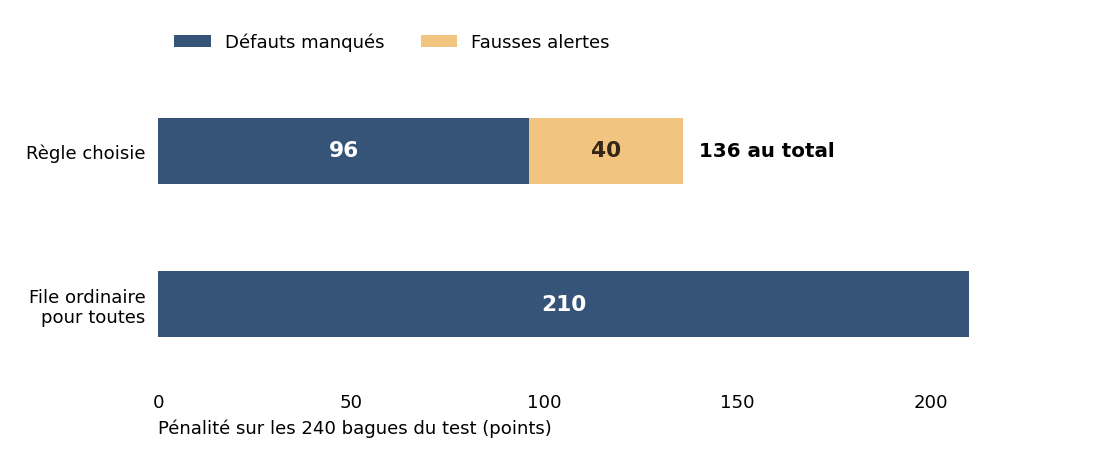

« À la sortie du tour, donnez la priorité aux bagues dont le score atteint 0,15 avec la régression logistique. Sur les 240 bagues du test, **59 passent en priorité**, dont **19 des 35 défectueuses** et **40 conformes**. Les **16 défectueuses restées dans la file ordinaire** coûtent 96 points et les fausses alertes 40, soit **136 points contre 210** si toutes les pièces suivent la file ordinaire. Je proposerais un essai sur des lots réels si l’équipe peut absorber cette charge de contrôles prioritaires. »

Avec **45 places**, il en aurait manqué **14** sur ce lot. Pour essayer une règle qui tienne compte de cette limite, reviens aux bagues de validation et écarte les choix qui dépassent la capacité. Réserve ensuite un nouveau lot pour juger la règle révisée.

</details>

## Retenir · Quatre décisions à pouvoir justifier

La responsable peut s’appuyer sur ton bilan pour décider d’un essai. Si elle te demande à quelles conditions tes chiffres restent utilisables, reprends les choix faits au cours du projet.

- **Le moment du tri.** La règle utilise les mesures disponibles à la sortie du tour. Une destination comme « rebut » n’est connue qu’après l’inspection.
- **Le prix des erreurs.** L’atelier compte six points pour un défaut manqué et un pour une fausse alerte. Changer ces coûts peut changer le seuil qu’il a intérêt à retenir.
- **Le rôle des trois lots.** Sur 720 pièces, la règle a appris à associer les mesures au verdict. Sur 240 autres, tu as choisi le modèle et le seuil. Tu as enfin chiffré ce choix sur les 240 pièces du test.
- **La décision de la responsable.** Sur ce test simulé, la règle économise **74 points** et demande **59 places prioritaires**. Si l’atelier dispose de ces places, il peut vérifier le gain sur des lots réels. Avec 45 places, le réglage doit être revu avant cet essai.